In [1]:
import matplotlib.pyplot as plt
import polars as pl

print("Military Maintenance Text Exploration")
print("Author: Brandon Smith")
print("Phase 5: Custom Application")

Military Maintenance Text Exploration
Author: Brandon Smith
Phase 5: Custom Application


In [2]:
corpus = [
    # Vehicles
    {"category": "vehicle", "text": "The truck engine failed inspection."},
    {"category": "vehicle", "text": "The vehicle battery requires replacement."},
    {"category": "vehicle", "text": "The truck has a brake system issue."},
    {"category": "vehicle", "text": "The vehicle engine requires maintenance."},
    {"category": "vehicle", "text": "The truck tire needs replacement."},
    {"category": "vehicle", "text": "The vehicle battery failed inspection."},
    # Communications
    {"category": "communications", "text": "The radio battery failed inspection."},
    {"category": "communications", "text": "The radio antenna requires replacement."},
    {
        "category": "communications",
        "text": "The communication system has signal issues.",
    },
    {"category": "communications", "text": "The radio requires maintenance."},
    {"category": "communications", "text": "The radio battery needs replacement."},
    {"category": "communications", "text": "The antenna failed inspection."},
    # Generators
    {"category": "generator", "text": "The generator engine requires maintenance."},
    {"category": "generator", "text": "The generator battery failed inspection."},
    {"category": "generator", "text": "The generator has a fuel system issue."},
    {"category": "generator", "text": "The generator requires oil replacement."},
    {"category": "generator", "text": "The generator engine failed inspection."},
    {"category": "generator", "text": "The fuel system requires maintenance."},
]

print(f"Corpus contains {len(corpus)} maintenance reports.")

Corpus contains 18 maintenance reports.


In [ ]:
def tokenize(text):
    """Convert maintenance report text into cleaned tokens."""
    tokens = text.lower().split()
    return [t.strip(".,:;!?()[]\"'") for t in tokens if len(t) > 2]


records = []

for doc in corpus:
    for token in tokenize(doc["text"]):
        records.append({"category": doc["category"], "token": token})

token_df = pl.DataFrame(records)

vocabulary_diversity_df = (
    token_df.group_by("category")
    .agg(
        pl.len().alias("total_words"),
        pl.col("token").n_unique().alias("unique_words"),
    )
    .with_columns(
        (pl.col("unique_words") / pl.col("total_words") * 100)
        .round(2)
        .alias("diversity_percent")
    )
    .sort("category")
)

print("Vocabulary Diversity by Equipment Category:")
print(vocabulary_diversity_df)

Vocabulary Diversity by Equipment Category:
shape: (3, 4)
┌────────────────┬─────────────┬──────────────┬───────────────────┐
│ category       ┆ total_words ┆ unique_words ┆ diversity_percent │
│ ---            ┆ ---         ┆ ---          ┆ ---               │
│ str            ┆ u64         ┆ u64          ┆ f64               │
╞════════════════╪═════════════╪══════════════╪═══════════════════╡
│ communications ┆ 29          ┆ 15           ┆ 51.72             │
│ generator      ┆ 31          ┆ 14           ┆ 45.16             │
│ vehicle        ┆ 31          ┆ 16           ┆ 51.61             │
└────────────────┴─────────────┴──────────────┴───────────────────┘


In [4]:
bigrams = []

for doc in corpus:
    tokens = tokenize(doc["text"])
    for i in range(len(tokens) - 1):
        bigrams.append(f"{tokens[i]} {tokens[i + 1]}")

bigram_df = pl.DataFrame({"bigram": bigrams})

bigram_freq_df = bigram_df.group_by("bigram").len().sort("len", descending=True)

print("Top 10 Maintenance Bigrams:")
print(bigram_freq_df.head(10))

Top 10 Maintenance Bigrams:
shape: (10, 2)
┌──────────────────────┬─────┐
│ bigram               ┆ len │
│ ---                  ┆ --- │
│ str                  ┆ u64 │
╞══════════════════════╪═════╡
│ failed inspection    ┆ 6   │
│ the generator        ┆ 5   │
│ requires maintenance ┆ 4   │
│ the radio            ┆ 4   │
│ battery failed       ┆ 3   │
│ the vehicle          ┆ 3   │
│ the truck            ┆ 3   │
│ requires replacement ┆ 2   │
│ system issue         ┆ 2   │
│ engine requires      ┆ 2   │
└──────────────────────┴─────┘


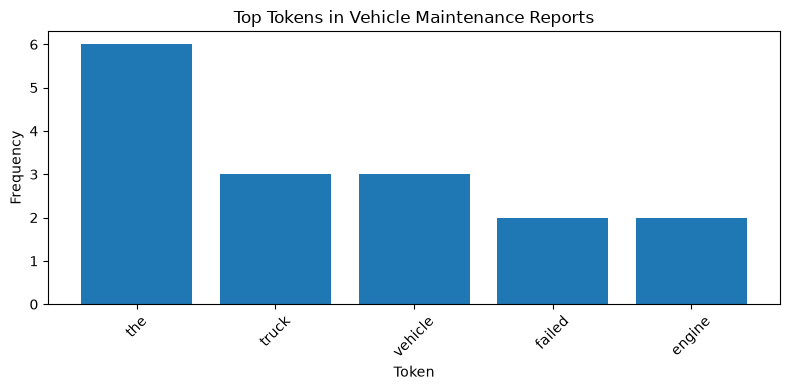

In [5]:
category_freq_df = (
    token_df.group_by(["category", "token"])
    .len()
    .sort(["category", "len"], descending=[False, True])
)

vehicle_df = category_freq_df.filter(pl.col("category") == "vehicle").head(5)

plt.figure(figsize=(8, 4))
plt.bar(vehicle_df["token"], vehicle_df["len"])
plt.title("Top Tokens in Vehicle Maintenance Reports")
plt.xlabel("Token")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()